# 🧩 LangGraph: Subgraphs with Shared State (Direct Mount Pattern)

### 📌 Overview
This notebook demonstrates **Subgraphs with Shared State Schemas**:
1. **Shared State Schema (`SharedState`):** Both the parent graph and the child subgraph read from and write to the exact same state channels.
2. **Direct Subgraph Mounting:** When schemas match, you do **not** need a bridge function. You pass the compiled child graph directly into `parent_builder.add_node("subgraph_node", compiled_subgraph)`.
3. **Automatic State Merging:** LangGraph automatically passes the global state into the subgraph, runs its internal multi-node topology, and merges updates back into the parent graph seamlessly.
4. **X-Ray Visualization (`xray=True`):** Demonstrates LangGraph's ability to "see inside" nested subgraphs and render the complete combined topology.

---

### 🗺️ Architecture (Directly Mounted Subgraph)

```text
 ┌──────────────────────────────────────────────────────────────────────────────────┐
 │ PARENT GRAPH                                                                     │
 │                                                                                  │
 │               ┌──────────────────────────────────────────────────┐               │
 │               │ SUBGRAPH: research_and_draft                     │               │
 │               │                                                  │               │
 │  ┌─────────┐  │  ┌───────────────┐     ┌──────────────────────┐  │  ┌─────────┐  │
 │  │  START  │ ─┼► │ analyze_topic │ ──► │  draft_initial_post  │ ─┼─►│   END   │  │
 │  └─────────┘  │  └───────────────┘     └──────────────────────┘  │  └─────────┘  │
 │               │                                                  │               │
 │               └──────────────────────────────────────────────────┘               │
 └──────────────────────────────────────────────────────────────────────────────────┘
```

*Key Advantage:* The child subgraph contains two internal nodes (`analyze_topic` ➔ `draft_initial_post`), but the parent graph mounts it as a single modular node.

In [1]:
import os
from typing import NotRequired, TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph

# Load environment variables
load_dotenv()

# Verify OpenRouter key
if not os.getenv("OPENROUTER_API_KEY"):
    raise ValueError(
        "OPENROUTER_API_KEY is missing. Please add it to your .env file: "
        "OPENROUTER_API_KEY=sk-or-v1-..."
    )

### 2. Initialize LLM via OpenRouter
We initialize `ChatOpenAI` pointing to OpenRouter's `openrouter/free` router at `temperature=0.3`.

In [2]:
# OpenRouter configuration with Free Models Router
model = ChatOpenAI(
    model="openrouter/free",
    api_key=os.getenv("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1",
    temperature=0.3,
)

### 3. Define the Shared State Schema
Both the parent graph and the child subgraph share this exact schema contract:
* `topic`: Initial prompt input.
* `key_insights`: Generated by Child Node 1 (`analyze_topic`).
* `draft`: Generated by Child Node 2 (`draft_initial_post`).
* `final_post`: Formatted by the Parent Node (`polish_and_finalize`).

In [3]:
class SharedState(TypedDict):
    topic: str
    key_insights: NotRequired[str]
    draft: NotRequired[str]
    final_post: NotRequired[str]

### 4. Build and Compile the Child Subgraph
This child subgraph is an independent, two-stage research and drafting engine:
1. **`analyze_topic`:** Breaks down the topic and identifies core technical arguments.
2. **`draft_initial_post`:** Consumes the topic and the newly generated `key_insights` to write a rough draft.

In [4]:
def analyze_topic(state: SharedState) -> dict:
    """Child Node 1: Analyzes the topic and extracts core arguments."""
    messages = [
        (
            "system",
            "You are a technical research analyst. Identify 2-3 key takeaways or insights on the topic.",
        ),
        ("human", f"Analyze this topic:\n\n{state['topic']}"),
    ]
    response = model.invoke(messages)
    return {"key_insights": str(response.content).strip()}


def draft_initial_post(state: SharedState) -> dict:
    """Child Node 2: Synthesizes the insights into an initial article draft."""
    messages = [
        (
            "system",
            "You are a technical writer. Draft a clear, cohesive 1-paragraph summary based on the provided insights.",
        ),
        (
            "human",
            f"Topic: {state['topic']}\n\nKey Insights:\n{state['key_insights']}\n\nDraft a summary:",
        ),
    ]
    response = model.invoke(messages)
    return {"draft": str(response.content).strip()}


# Build and compile the Child Subgraph
subgraph_builder = StateGraph(SharedState)
subgraph_builder.add_node("analyze_topic", analyze_topic)
subgraph_builder.add_node("draft_initial_post", draft_initial_post)

subgraph_builder.add_edge(START, "analyze_topic")
subgraph_builder.add_edge("analyze_topic", "draft_initial_post")
subgraph_builder.add_edge("draft_initial_post", END)

# Compile as an independent runnable
subgraph = subgraph_builder.compile()

### 5. Inspect and Test the Child Subgraph Standalone
Because `subgraph` is a compiled `StateGraph`, we can invoke and visualize it independently before mounting it to the parent.

Child Subgraph Insights:
Based on technical analysis of real-world implementations, trade-offs, and organizational impacts, here are **2-3 key, actionable takeaways** comparing Event-Driven Microservices (EDM) vs. Monoliths, focusing on *where each approach genuinely succeeds or fails in practice*:

### 1. **Operational Complexity vs. Development Velocity: The Hidden Tax**  
   - **EDM Insight**: While EDM excels at *independent deployability* and *fault isolation* (e.g., a payment service failure doesn’t crash user profiles), it imposes a significant **operational complexity tax** that often outweighs benefits for early/mid-stage systems. Debugging distributed traces, managing eventual consistency, schema evolution across services, and monitoring 50+ interconnected services require mature DevOps, SRE, and observability tooling (e.g., OpenTelemetry, service meshes). Teams frequently underestimate this cost—leading to "distributed monoliths" where services are tightly coupled via events

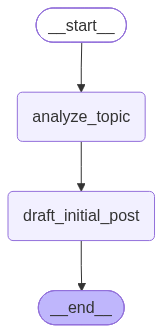

In [5]:
# Standalone execution test
standalone_test = subgraph.invoke({"topic": "Event-Driven Microservices vs Monoliths"})
print(f"Child Subgraph Insights:\n{standalone_test['key_insights']}\n")
print(f"Child Subgraph Draft:\n{standalone_test['draft']}\n")

# Render child topology
subgraph

### 6. Build the Parent Graph with Direct Subgraph Mount
Notice the key difference here:
* We add a parent polishing node: `polish_and_finalize`.
* We mount the compiled `subgraph` **directly as a node** using `parent_builder.add_node("research_and_draft", subgraph)`!
* No wrapper function, no manual `.invoke()`, and no state dictionary transformations are needed.

In [6]:
def polish_and_finalize(state: SharedState) -> dict:
    """Parent Node: Formats the draft produced by the subgraph into an executive publication."""
    messages = [
        (
            "system",
            "You are an executive editor. Polish the draft into an executive LinkedIn post with an engaging hook and 2-3 hashtags.",
        ),
        ("human", f"Draft:\n{state['draft']}"),
    ]
    response = model.invoke(messages)
    return {"final_post": str(response.content).strip()}


# Build Parent Graph
parent_builder = StateGraph(SharedState)

# 👉 DIRECT MOUNT: Pass the compiled subgraph directly as a node!
parent_builder.add_node("research_and_draft", subgraph)
parent_builder.add_node("polish_and_finalize", polish_and_finalize)

# Wire the parent pipeline
parent_builder.add_edge(START, "research_and_draft")
parent_builder.add_edge("research_and_draft", "polish_and_finalize")
parent_builder.add_edge("polish_and_finalize", END)

# Compile Parent Graph
parent_graph = parent_builder.compile()

### 7. Visualize Parent Topology (Standard vs. X-Ray View)
* **Standard View:** Displays the subgraph as a single unified node box (`research_and_draft`).
* **X-Ray View (`xray=True`):** LangGraph's visualizer unrolls the internal nodes of the child subgraph (`analyze_topic` ➔ `draft_initial_post`) directly inside the parent diagram!

--- Standard View (Collapsed Subgraph) ---


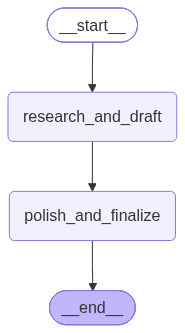

--- X-Ray View (Unrolled Subgraph Internal Nodes) ---


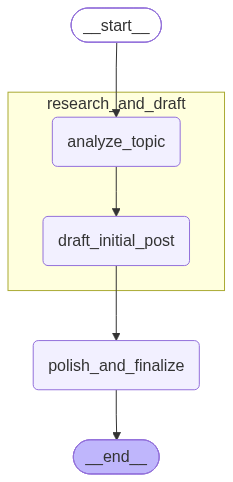

In [7]:
# 1. Standard Parent View (Collapsed)
print("--- Standard View (Collapsed Subgraph) ---")
display(Image(parent_graph.get_graph().draw_mermaid_png()))

# 2. X-Ray View (Unfolded internal subgraph nodes)
print("--- X-Ray View (Unrolled Subgraph Internal Nodes) ---")
display(Image(parent_graph.get_graph(xray=True).draw_mermaid_png()))

### 8. Execute the Full Hierarchical Workflow
We invoke `parent_graph`. State seamlessly flows from `START` into the child subgraph's internal nodes, updates `key_insights` and `draft`, returns to the parent node to generate `final_post`, and exits at `END`.

In [8]:
initial_input = {"topic": "Why Vector Databases are Essential for Large Language Models"}

print("=== EXECUTING HIERARCHICAL WORKFLOW WITH DIRECT SUBGRAPH MOUNT ===\n")
final_state = parent_graph.invoke(initial_input)

print("=" * 60)
print(f"1. TOPIC:\n{final_state['topic']}\n")
print("=" * 60)
print(f"2. KEY INSIGHTS (Produced by Subgraph Node 1):\n{final_state['key_insights']}\n")
print("=" * 60)
print(f"3. DRAFT (Produced by Subgraph Node 2):\n{final_state['draft']}\n")
print("=" * 60)
print(f"4. FINAL POLISHED PUBLICATION (Produced by Parent Node):\n{final_state['final_post']}")

=== EXECUTING HIERARCHICAL WORKFLOW WITH DIRECT SUBGRAPH MOUNT ===

1. TOPIC:
Why Vector Databases are Essential for Large Language Models

2. KEY INSIGHTS (Produced by Subgraph Node 1):
**Key Takeaways – Why Vector Databases Are Essential for Large Language Models**

1. **Fast, Scalable Semantic Retrieval for RAG**  
   - LLMs excel at generation but rely on external knowledge for up‑to‑date, domain‑specific information.  
   - Vector databases store dense embeddings (e.g., from LLM‑generated or pre‑trained encoders) and provide sub‑linear, approximate nearest‑neighbor (ANN) search (HNSW, IVF‑PQ, etc.).  
   - This enables Retrieval‑Augmented Generation (RAG) pipelines to locate relevant context in milliseconds, even when the corpus contains billions of vectors, without overwhelming the model’s context window.

2. **Decoupling of Computation and Storage, Enabling Real‑Time Updates**  
   - Traditional databases (SQL/NoSQL) are not optimized for high‑dimensional similarity queries; re‑